# ChronoPack demo: K562 cells responding to TNF-α

This notebook runs the core ChronoPack workflow on one single-cell time course: K562 cells sampled every 10 minutes for 110 minutes after TNF-α stimulation (12 time points, 6,857 cells). Starting from preprocessed data, it

1. reconstructs **cell-state trajectories** with optimal transport and finds the two fates the cells take;
2. **prepares the counts** for gene-dynamics fits, removing genes distorted by the time-point tags;
3. **fits gene dynamics** along time with negative-binomial GAMs (tradeSeq), once for all cells and once per fate;
4. **visualizes** the trajectories, the genes that change over time and their fate-specific curves.

Like Scanpy, ChronoPack has `cp.tl` for analysis tools, which add their results to an AnnData object, and `cp.pl` for plots.

**Runtime.** About 20 minutes on 4 cores, most of it in the tradeSeq fits. To keep it short, the gene-dynamics fits use a subset of genes (`N_GENES` below). The full analysis in `analyses/k562-tnfa.hg38.rep/` fits all ~12,000 genes and takes a few hours.

**Requirements.** The ChronoPack environment with its R packages (see the main README), and three input files in `demo/data/` (or the folder set by `CHRONOPACK_DEMO_DATA`):

| File | Contents |
|---|---|
| `k562_tnfa.hvg.h5ad` | 3,000 highly variable genes, corrected expression |
| `k562_tnfa.counts.h5ad` | all genes, raw UMI counts |
| `k562_neg-ctrl_mtx-agg.pkl` | negative-control pseudobulk for the time-tag check |

Everything the notebook computes (transport maps, tradeSeq fits, figures) goes to `demo/work/` (or `CHRONOPACK_DEMO_WORK`).

In [1]:
import os
from pathlib import Path

import pandas as pd
import scanpy as sc

import chronopack as cp

DATA_DIR = Path(os.environ.get("CHRONOPACK_DEMO_DATA", "data"))
WORK_DIR = Path(os.environ.get("CHRONOPACK_DEMO_WORK", "work"))
TRADESEQ_DIR = WORK_DIR / "tradeseq"
FIG_DIR = WORK_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

N_GENES = 300         # genes fitted with tradeSeq
WORKERS = 4           # parallel R workers for tradeSeq
MINUTES_PER_TAG = 10  # time between consecutive time points

## 1. The preprocessed data

Preprocessing (quality control, doublet removal, normalization; `analyses/k562-tnfa.hg38.rep/01_PreprocessDatasets.ipynb`) gives two views of the same cells:

- `adata_hvg`: the 3,000 most variable genes, with expression corrected for library size, mitochondrial fraction, cell cycle and sample. The trajectories are computed from this.
- `adata`: all genes as raw UMI counts (`layers["counts"]`). The gene dynamics are fitted on these, because tradeSeq models counts directly.

In both, `obs["time"]` is the time point (1-12).

In [2]:
adata_hvg = sc.read_h5ad(DATA_DIR / "k562_tnfa.hvg.h5ad")
adata = sc.read_h5ad(DATA_DIR / "k562_tnfa.counts.h5ad")
print(adata_hvg)
print(adata)

AnnData object with n_obs × n_vars = 6857 × 3000
    obs: 'sample', 'time', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'phase'
    var: 'highly_variable', 'dispersions_norm'
    obsm: 'X_umap'
AnnData object with n_obs × n_vars = 6857 × 20036
    obs: 'sample', 'time', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'phase'
    var: 'highly_variable', 'dispersions_norm'
    layers: 'counts'


In [3]:
pd.crosstab(adata.obs["time"], adata.obs["sample"], margins=True).T

time,1,2,3,4,5,6,7,8,9,10,11,12,All
sample,,,,,,,,,,,,,
N701,178,185,128,138,128,97,199,160,132,148,132,164,1789
N702,149,174,109,157,91,109,184,162,127,173,136,137,1708
N703,153,165,98,130,119,95,202,157,119,151,163,138,1690
N704,161,141,122,145,106,100,186,141,127,128,162,151,1670
All,641,665,457,570,444,401,771,620,505,600,593,590,6857


On the standard UMAP from preprocessing, coloured by time point and by two marker genes: *NFKBIA*, an NF-κB target induced by TNF-α, and *HBG2* (fetal haemoglobin), an erythroid marker.

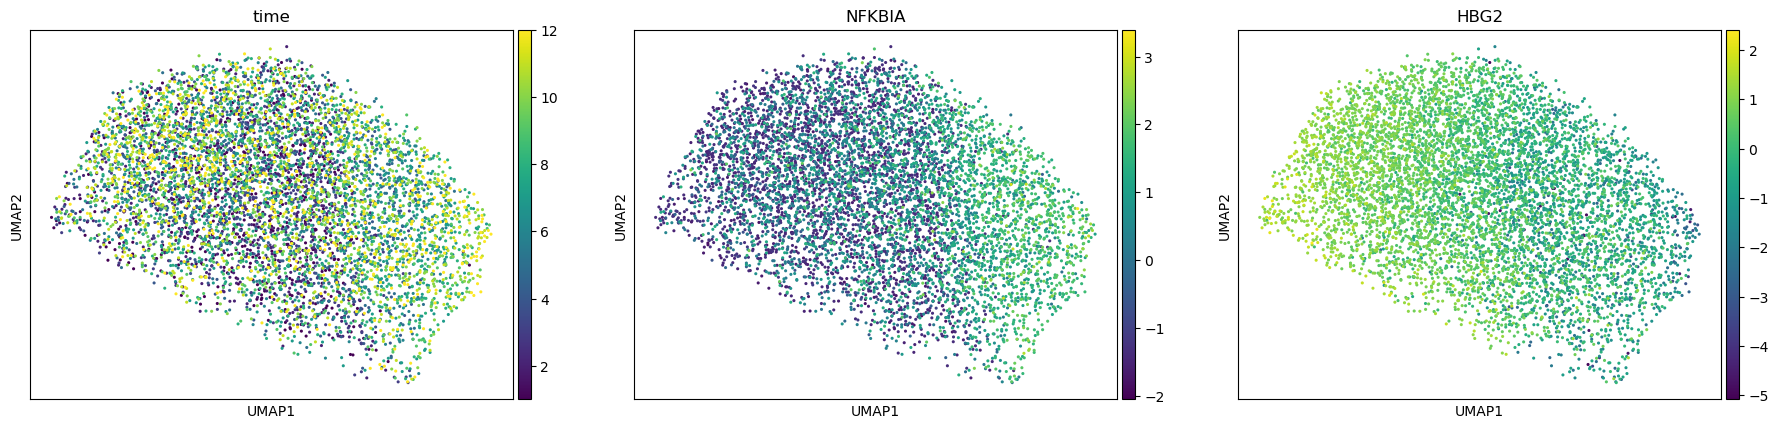

In [4]:
sc.pl.umap(adata_hvg, color=["time", "NFKBIA", "HBG2"], cmap="viridis", size=20)

## 2. Cell-state trajectories

`cp.tl.get_trajectories` runs [Waddington-OT](https://broadinstitute.github.io/wot/): for each pair of consecutive time points, it computes a transport map, a probabilistic coupling of each cell to the cells it is likely to become at the next time point. ChronoPack turns the maps into one cell-to-cell transition graph (keeping each cell's top 30 transitions; `obsp["ot_graph"]`) and lays the graph out as the **OT-UMAP** (`obsm["ot_umap"]`), in which cells sit near their likely ancestors and descendants. The transport maps are saved to `work/tmaps/`.

In [5]:
trajectories = cp.tl.get_trajectories(
    adata_hvg,
    tmap_dir=WORK_DIR / "tmaps",
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3),
    transition_topk=30,
    umap_random_state=10,
)
adata_hvg

Built 11 transport matrices.


/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/scanpy/tools/_umap.py:204: UserWarning: You’re trying to run this on 3000 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(


AnnData object with n_obs × n_vars = 6857 × 3000
    obs: 'sample', 'time', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'phase'
    var: 'highly_variable', 'dispersions_norm'
    uns: 'ot_graph', 'umap', 'pca', 'chronopack'
    obsm: 'X_umap', 'X_pca', 'ot_umap'
    varm: 'PCs'
    obsp: 'ot_graph'

`cp.tl.rotate_embedding_to_time` rotates the OT-UMAP so that time runs upward (stored as `obsm["ot_umap_rot"]`), and `cp.pl.cell_trajectories.time_minutes` colours it by time in minutes.

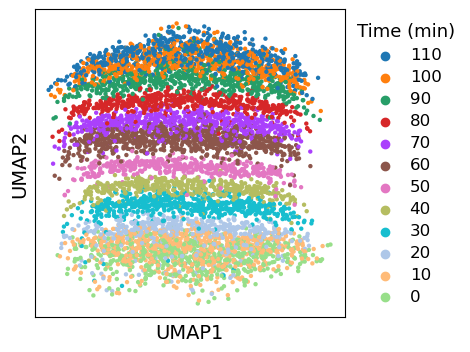

In [6]:
BASIS = cp.tl.rotate_embedding_to_time(adata_hvg, basis="ot_umap", key_added="ot_umap_rot", flip_x=True)
fig = cp.pl.cell_trajectories.time_minutes(
    adata_hvg, embedding_basis=BASIS, minutes_per_tag=MINUTES_PER_TAG, size=40, output=FIG_DIR / "umap_time.pdf"
)

### Trajectory clusters

`cp.tl.cluster_cells_to_trajectories` follows the transition graph forward from every cell to where its descendants end up at the last time point, and clusters the cells by these destinations (`obs["traj_clusters"]`). Two trajectories emerge:

In [7]:
cp.tl.cluster_cells_to_trajectories(adata_hvg, trajectories.T_pruned, resolution=0.3, random_state=0)
adata_hvg.obs["traj_clusters"].value_counts()

Terminal timepoint: 12 | n_terminal=590
Computed terminal distributions for time bin 11/12 (n=593)
Computed terminal distributions for time bin 10/12 (n=600)
Computed terminal distributions for time bin 9/12 (n=505)
Computed terminal distributions for time bin 8/12 (n=620)
Computed terminal distributions for time bin 7/12 (n=771)
Computed terminal distributions for time bin 6/12 (n=401)
Computed terminal distributions for time bin 5/12 (n=444)
Computed terminal distributions for time bin 4/12 (n=570)
Computed terminal distributions for time bin 3/12 (n=457)
Computed terminal distributions for time bin 2/12 (n=665)
Computed terminal distributions for time bin 1/12 (n=641)
Stored adata.obsm['terminal_cell_dist'] with shape (6857, 590) (sparse nnz=3194104)


/new-stg/home/alex/tmp/ChronoPack/src/chronopack/tl/_trajectories.py:610: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  _scanpy().tl.leiden(


traj_clusters
0    3618
1    3239
Name: count, dtype: int64

Trajectory `0` ends in cells with a strong NF-κB response (high *NFKBIA*) and trajectory `1` in cells with a weak response and erythroid features (high *HBG2*):

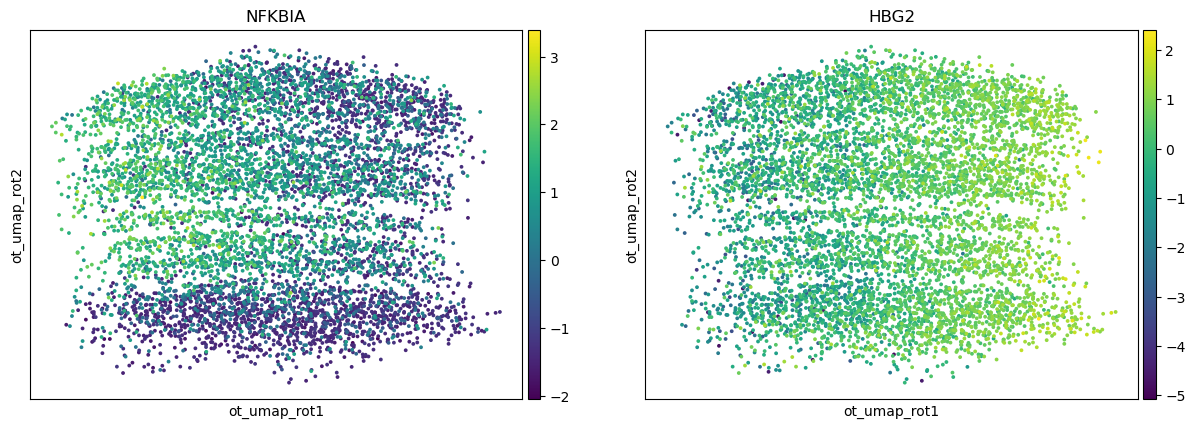

In [8]:
sc.pl.embedding(adata_hvg, basis=BASIS, color=["NFKBIA", "HBG2"], cmap="viridis", size=30)

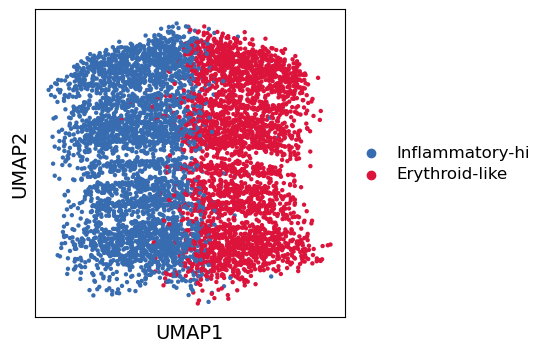

In [9]:
FATE_NAMES = {"0": "Inflammatory-hi", "1": "Erythroid-like"}
FATE_COLORS = {"Inflammatory-hi": "#386cb0", "Erythroid-like": "#DC143C"}

fig = cp.pl.cell_trajectories.trajectory_cell_types(
    adata_hvg,
    labels=FATE_NAMES,
    palette=list(FATE_COLORS.values()),
    embedding_basis=BASIS,
    size=40,
    output=FIG_DIR / "umap_trajectories.pdf",
)

### Fate probabilities

`cp.tl.compute_terminal_fate_probabilities` gives each cell its probability of ending in each trajectory (`obsm["terminal_fate_probs_traj"]`). Below: the probability of the erythroid-like fate (red) and of the inflammatory fate (blue), then the normalized fate entropy and the maximum fate probability. Most cells already lean clearly towards one fate at the earliest time points; cells between the two trajectories have intermediate probabilities (high entropy, low maximum probability).

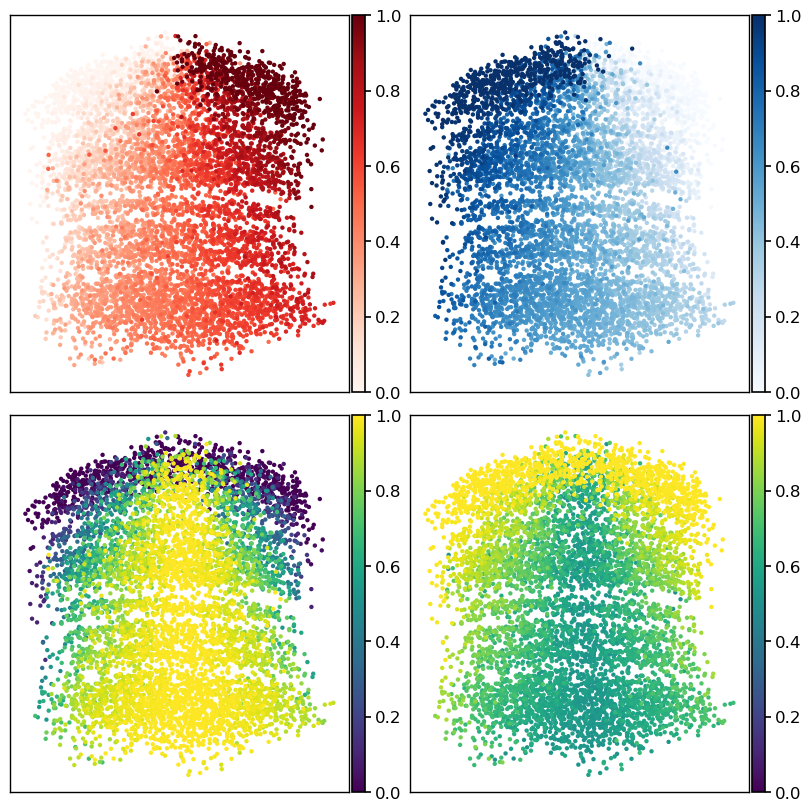

In [10]:
cp.tl.compute_terminal_fate_probabilities(adata_hvg)
fig = cp.pl.cell_trajectories.fate_probability_panels(
    adata_hvg, embedding_basis=BASIS, which_two=(1, 0), size=40, figsize=(8, 8), output=FIG_DIR / "umap_fates.pdf"
)

### Soft memberships

Because early cells have not yet committed, the per-fate gene fits weight each cell by its membership of each trajectory rather than assigning it to one. `cp.pl.cell_trajectories.mass_retention` measures how much of each cell's forward transport mass stays within its own trajectory (stored in `obs["traj_clusters_mass_ret_cell"]`), and `cp.tl.trajectory_soft_memberships` turns that into two membership weights per cell.

/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


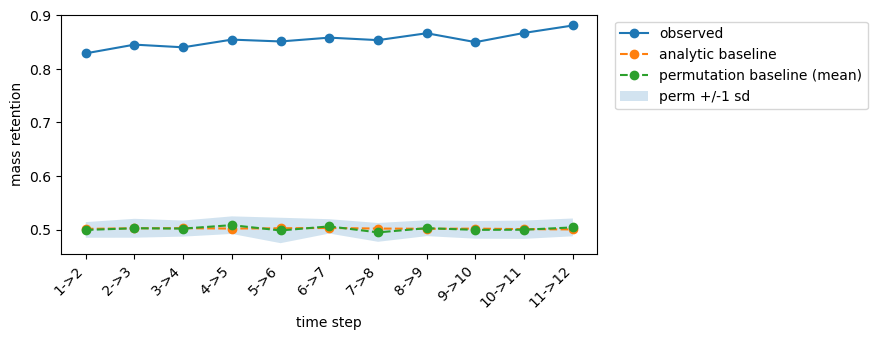

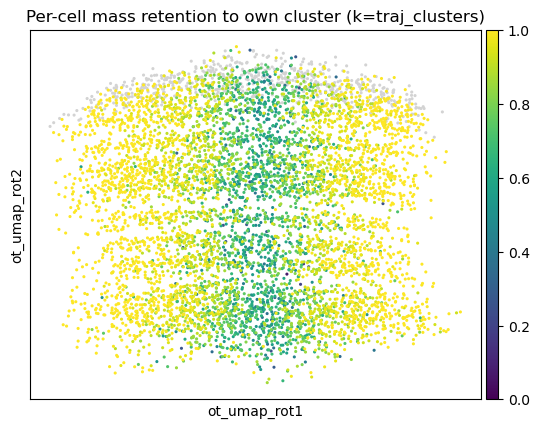

In [11]:
retention = cp.pl.cell_trajectories.mass_retention(
    adata_hvg, S=trajectories.T_pruned, n_reps=50, clusters_to_plot=["0", "1"], embedding_basis=BASIS, size=20
)

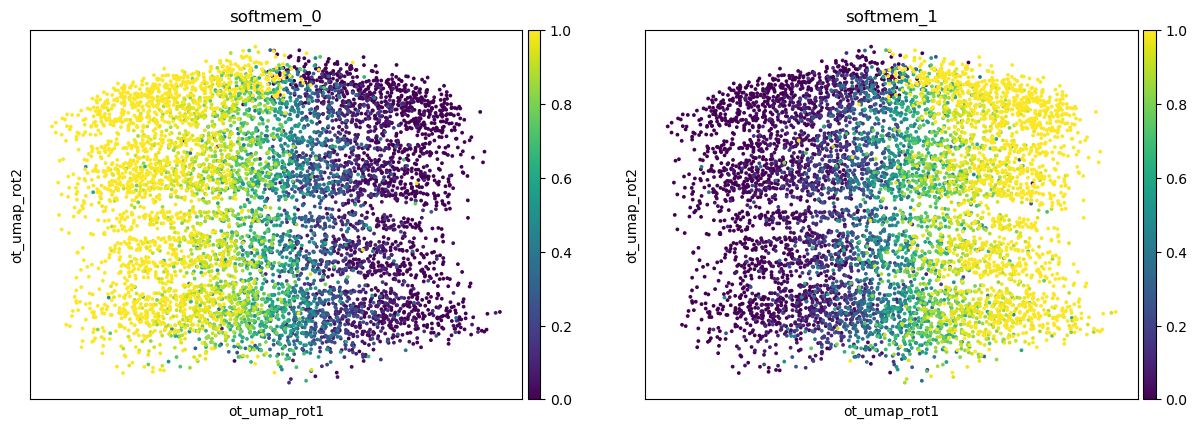

In [12]:
memberships = cp.tl.trajectory_soft_memberships(adata_hvg)
sc.pl.embedding(adata_hvg, basis=BASIS, color=["softmem_0", "softmem_1"], cmap="viridis", size=30)

Cells at the outer edges belong (almost) entirely to their own trajectory, while cells between the two trajectories split their weight. `memberships` (cells x trajectories) goes into the gene-dynamics fits below. The hard trajectory-cluster proportions stay similar over time:

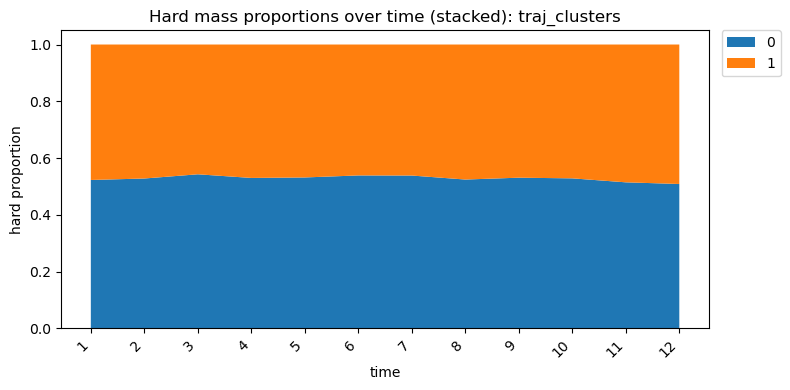

In [13]:
cp.pl.cell_trajectories.proportions_over_time(adata_hvg)

## 3. Prepare the counts for gene-dynamics fits

The gene dynamics are fitted on the raw counts of all genes, after removing genes that would give misleading curves.

**Time-tag bias.** Each time point is labelled with its own tag sequence, and the tags capture some genes more efficiently than others. `cp.tl.identify_tag_bias_candidates` compares each gene's time profile (pseudobulk per time point) with its profile across the same tags in a negative-control sample. It flags genes whose tag-to-tag fluctuations, around a smooth trend, follow the control (r ≥ 0.7, explaining ≥ 25% of the variance), because those changes come from the tags rather than from TNF-α.

In [14]:
tag_bias = cp.tl.identify_tag_bias_candidates(
    adata,
    DATA_DIR / "k562_neg-ctrl_mtx-agg.pkl",
    local_r_threshold=0.7,
    local_fraction_threshold=0.25,
)
tag_bias_genes = cp.tl.tag_bias_exclusion_genes(tag_bias)
print(f"{len(tag_bias_genes)} of {len(tag_bias)} genes are time-tag-biased")

1025 of 19137 genes are time-tag-biased


`cp.io.filter_technical_genes` removes these together with mitochondrial, ribosomal-protein and unnamed (`ENSG...`) genes, and `cp.io.filter_low_count_genes` removes genes with fewer than 10 counts in total.

In [15]:
n_before = adata.n_vars
cp.io.filter_technical_genes(adata, exclude_genes=tag_bias_genes)
cp.io.filter_low_count_genes(adata, min_total_counts=10)
print(f"{n_before} -> {adata.n_vars} genes")

20036 -> 11866 genes


**Gene subset for the demo.** The fits below use the `N_GENES` most variable remaining genes (normalized dispersion from preprocessing) plus eight NF-κB and stress-response genes that are plotted at the end. Set `N_GENES = adata.n_vars` to fit all genes, as the full analysis does.

In [16]:
PANEL = ["NFKBIA", "NFKB2", "ICAM1", "BIRC3", "CXCL3", "CD69", "IFNGR2", "DDIT4"]

most_variable = adata.var["dispersions_norm"].drop(PANEL).nlargest(N_GENES - len(PANEL)).index
adata_fit = adata[:, adata.var_names.isin(PANEL) | adata.var_names.isin(most_variable)].copy()
adata_fit

AnnData object with n_obs × n_vars = 6857 × 300
    obs: 'sample', 'time', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'phase'
    var: 'highly_variable', 'dispersions_norm', 'total_counts'
    uns: 'chronopack'
    layers: 'counts'

## 4. Fit gene dynamics

### All cells

`cp.tl.fit_gene_dynamics` fits each gene's counts along time with a negative-binomial GAM (tradeSeq), with time points scaled to pseudotime 0-1 and each cell's library size as an offset. It

1. writes the tradeSeq inputs to `work/tradeseq/` (`prepare_inputs=True`; `cell_weights` is saved there for the per-fate fit below);
2. fits every gene with 4 knots and tests whether its expression changes over time (association test, `waldStat_1`, `pvalue_1`, `qval_1`);
3. refits the genes with p < 0.05 with 8 knots, for the curves.

The test results are returned (`fit.association`) and added to `adata_fit.var`; the fitted models are saved as R objects (`fit.sidecar_paths`).

In [17]:
fit = cp.tl.fit_gene_dynamics(
    adata_fit,
    output_dir=TRADESEQ_DIR,
    prepare_inputs=True,
    cell_weights=memberships,
    workers=WORKERS,
    verbose=False,
)
print(f"{len(fit.association)} genes tested, {(fit.association['qval_1'] < 0.01).sum()} change over time (q < 0.01), "
      f"{len(fit.selected_genes)} refitted with 8 knots")
fit.association.sort_values("waldStat_1", ascending=False).head(10)

300 genes tested, 76 change over time (q < 0.01), 111 refitted with 8 knots


,waldStat_1,df_1,pvalue_1,meanLogFC,qval_1
NFKBIA,1967.377557,3,0.0,2.806293,0.0
CXCL3,742.323899,3,0.0,2.786376,0.0
CD69,602.364734,3,0.0,3.454632,0.0
CD83,566.998711,3,0.0,2.128998,0.0
ICAM1,439.214218,3,0.0,2.905745,0.0
CXCL8,426.558033,3,0.0,3.112823,0.0
BTG2,351.109650,3,0.0,1.755263,0.0
BIRC3,322.016923,3,0.0,3.600900,0.0
DDIT4,302.262651,3,0.0,1.338890,0.0
EGR1,292.113536,3,0.0,0.888027,0.0


### One curve per trajectory

With `lineage_weights`, the same function fits one curve per trajectory. The soft memberships become tradeSeq cell weights, so an uncommitted early cell contributes to both curves. The association table now has a global test (`waldStat`, `qval`) and one test per trajectory (`_1`: inflammatory, `_2`: erythroid-like).

In [18]:
fit_fates = cp.tl.fit_gene_dynamics(
    adata_fit,
    input_dir=TRADESEQ_DIR,
    lineage_weights="cell_weights.csv",
    key_added="gene_dynamics_fates",
    workers=WORKERS,
    verbose=False,
)
fit_fates.association.sort_values("waldStat", ascending=False)[
    ["waldStat", "qval", "waldStat_1", "qval_1", "waldStat_2", "qval_2"]
].head(10)

,waldStat,qval,waldStat_1,qval_1,waldStat_2,qval_2
NFKBIA,2195.501537,0.0,1415.958568,0.0,779.542970,0.000000e+00
CXCL3,771.487803,0.0,620.243782,0.0,151.244020,0.000000e+00
CD69,665.543339,0.0,491.040239,0.0,174.503100,0.000000e+00
CD83,569.496943,0.0,459.791422,0.0,109.705521,0.000000e+00
CXCL8,444.511275,0.0,355.368256,0.0,89.143019,0.000000e+00
ICAM1,442.270860,0.0,379.806636,0.0,62.464224,3.085767e-12
BTG2,344.810093,0.0,246.388153,0.0,98.421939,0.000000e+00
BIRC3,309.262367,0.0,259.920276,0.0,49.342090,1.741672e-09
EGR1,308.361716,0.0,201.538268,0.0,106.823448,0.000000e+00
DDIT4,306.509750,0.0,125.289458,0.0,181.220292,0.000000e+00


Genes that change over time (q < 0.01) in each trajectory:

In [19]:
changes = fit_fates.association[["qval_1", "qval_2"]] < 0.01
pd.crosstab(
    changes["qval_1"].map({True: "changes", False: "-"}).rename(FATE_NAMES["0"]),
    changes["qval_2"].map({True: "changes", False: "-"}).rename(FATE_NAMES["1"]),
)

Erythroid-like,-,changes
Inflammatory-hi,,
-,232,7
changes,23,38


## 5. Visualize gene dynamics

### Which genes change over time?

Volcano of the all-cells association test: the y-axis is the Wald statistic, the x-axis each gene's largest log2 fold change from the start of its fitted curve (`cp.tl.signed_max_log2fc_from_start`). Genes with q < 0.01 and |log2FC| ≥ 0.5 are coloured by direction, and the top 15 genes by Wald statistic are labelled. The axis is compressed below the dashed line, the Wald statistic at q = 0.01.

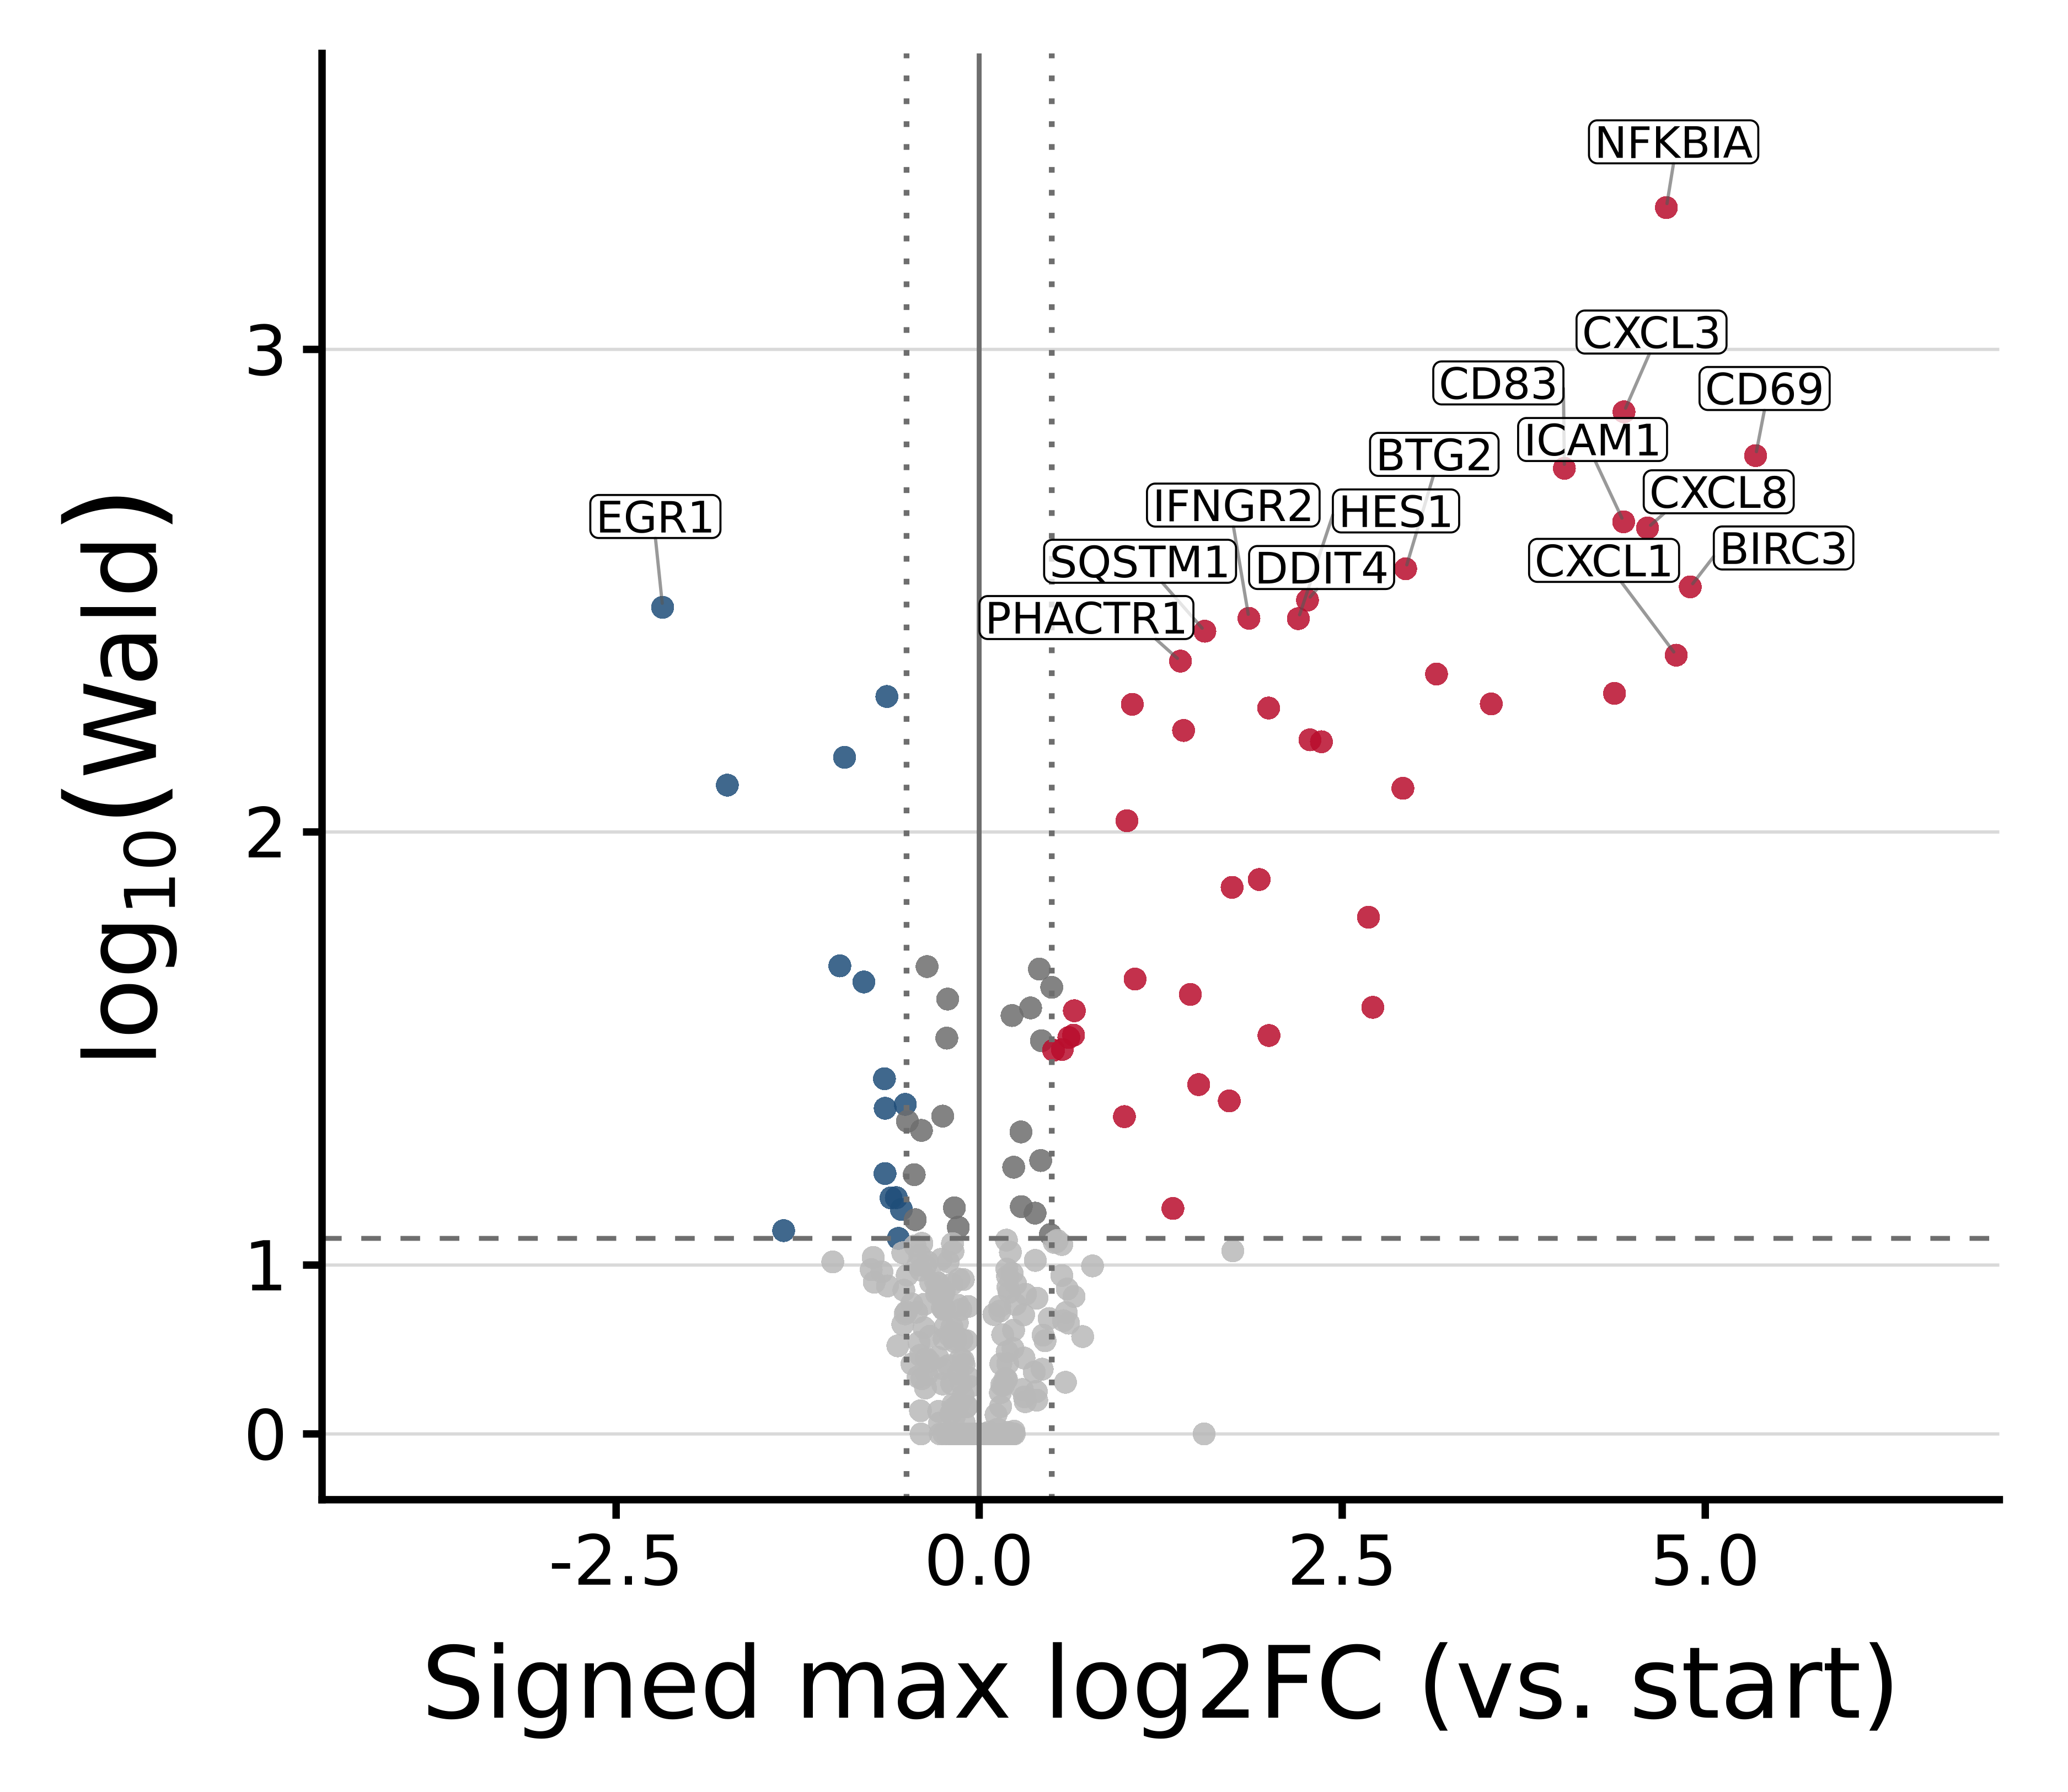

In [20]:
asso = fit.association.copy()
asso["signedMaxLog2FC_start"] = cp.tl.signed_max_log2fc_from_start(fit, asso.index)
cp.pl.association_volcano(
    asso,
    fdr_thresh=0.01,
    l2fc_thresh=0.5,
    x_lim=(-4, 6.5),
    y_lim=(1, 3000),
    top_labels=15,
    label_size=4,
    output=FIG_DIR / "volcano.pdf",
)

### Fitted curves of the top genes

`cp.tl.predict_gene_dynamics` evaluates the fitted curves (with 95% bands) on a time grid, and `cp.tl.observed_gene_dynamics` gives each cell's expression on the same scale (counts scaled to a common library size, log1p). `cp.pl.gene_dynamics_curves` plots them: the cells as points, the curve and band, and the mean per time point as white circles. Here, the eight genes that change most over time:

R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1:   
R callback write-console: In RNGkind("Mersenne-Twister", "Inversion", "Rounding") :  
R callback write-console: 
   
R callback write-console:  non-uniform 'Rounding' sampler used
  
R callback write-console: 2:   
R callback write-console: In RNGkind("Mersenne-Twister", "Inversion", "Rounding") :  
R callback write-console: 
   
R callback write-console:  non-uniform 'Rounding' sampler used
  


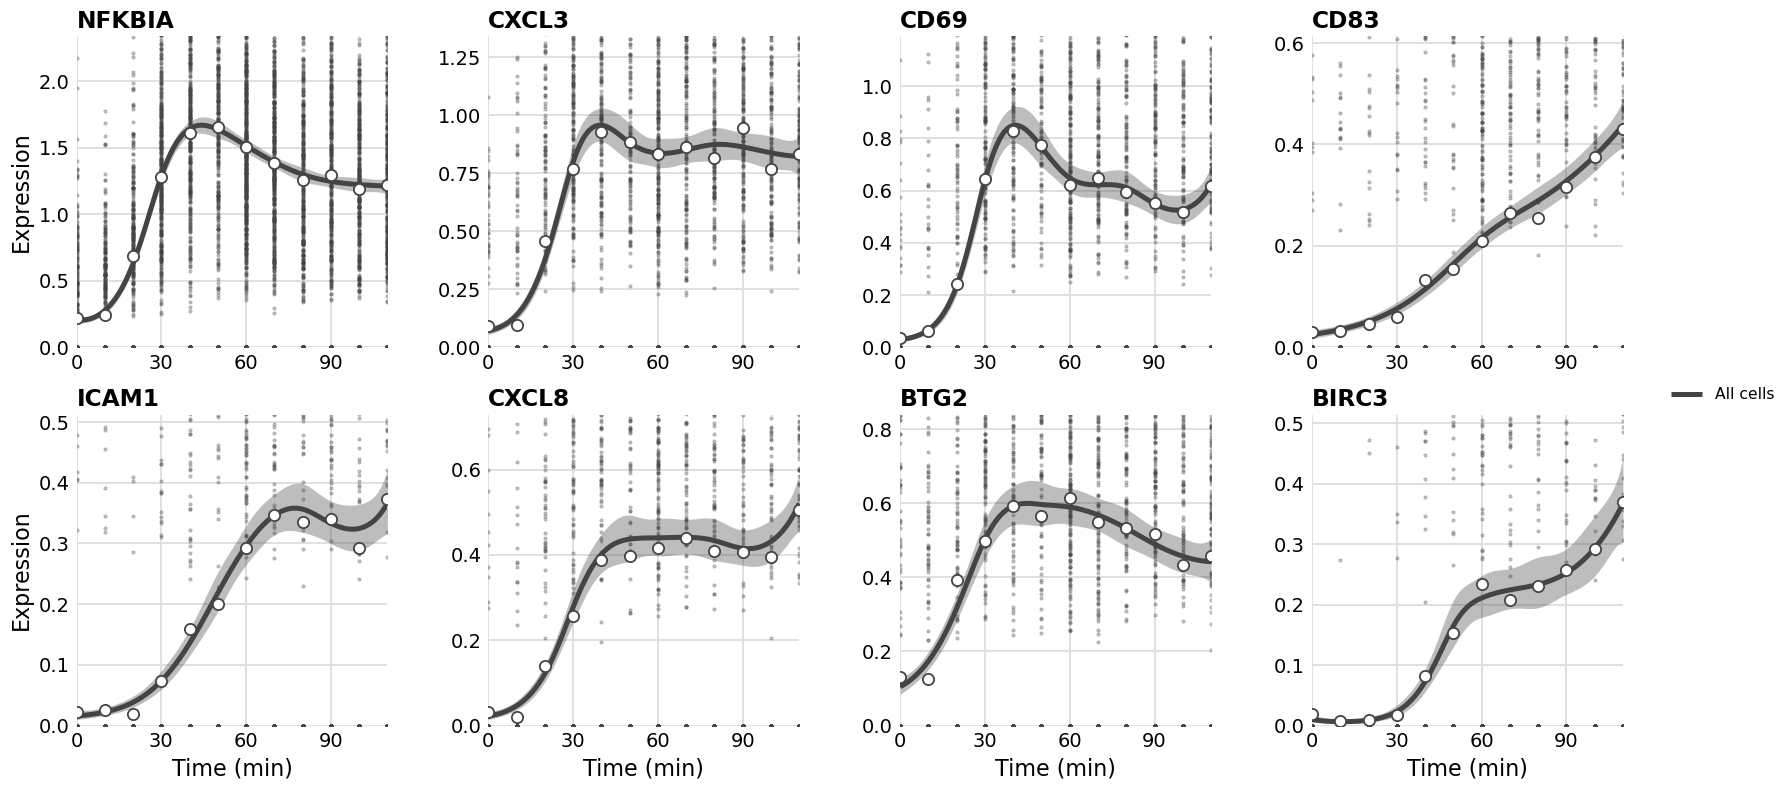

In [21]:
TIME_MAX = (adata.obs["time"].max() - adata.obs["time"].min()) * MINUTES_PER_TAG
top_genes = fit.association.loc[fit.selected_genes, "waldStat_1"].nlargest(8).index.tolist()

fig = cp.pl.gene_dynamics_curves(
    cp.tl.predict_gene_dynamics(fit, top_genes, time_max=TIME_MAX).assign(group="All cells"),
    top_genes,
    observations=cp.tl.observed_gene_dynamics(fit, top_genes, time_max=TIME_MAX).assign(group="All cells"),
    group_col="group",
    colors={"All cells": "#444444"},
    output=FIG_DIR / "top_gene_curves.pdf",
)

### Fate-specific curves

The per-trajectory fit for the eight panel genes. Cells are coloured by the trajectory they belong to most, and each trajectory's means are weighted by the cells' memberships. The NF-κB targets *NFKBIA*, *ICAM1*, *BIRC3*, *CXCL3* and *CD69* are induced much more strongly in the inflammatory trajectory and *IFNGR2* somewhat more, while *DDIT4* rises similarly in both; *NFKB2* is barely detected in these cells.

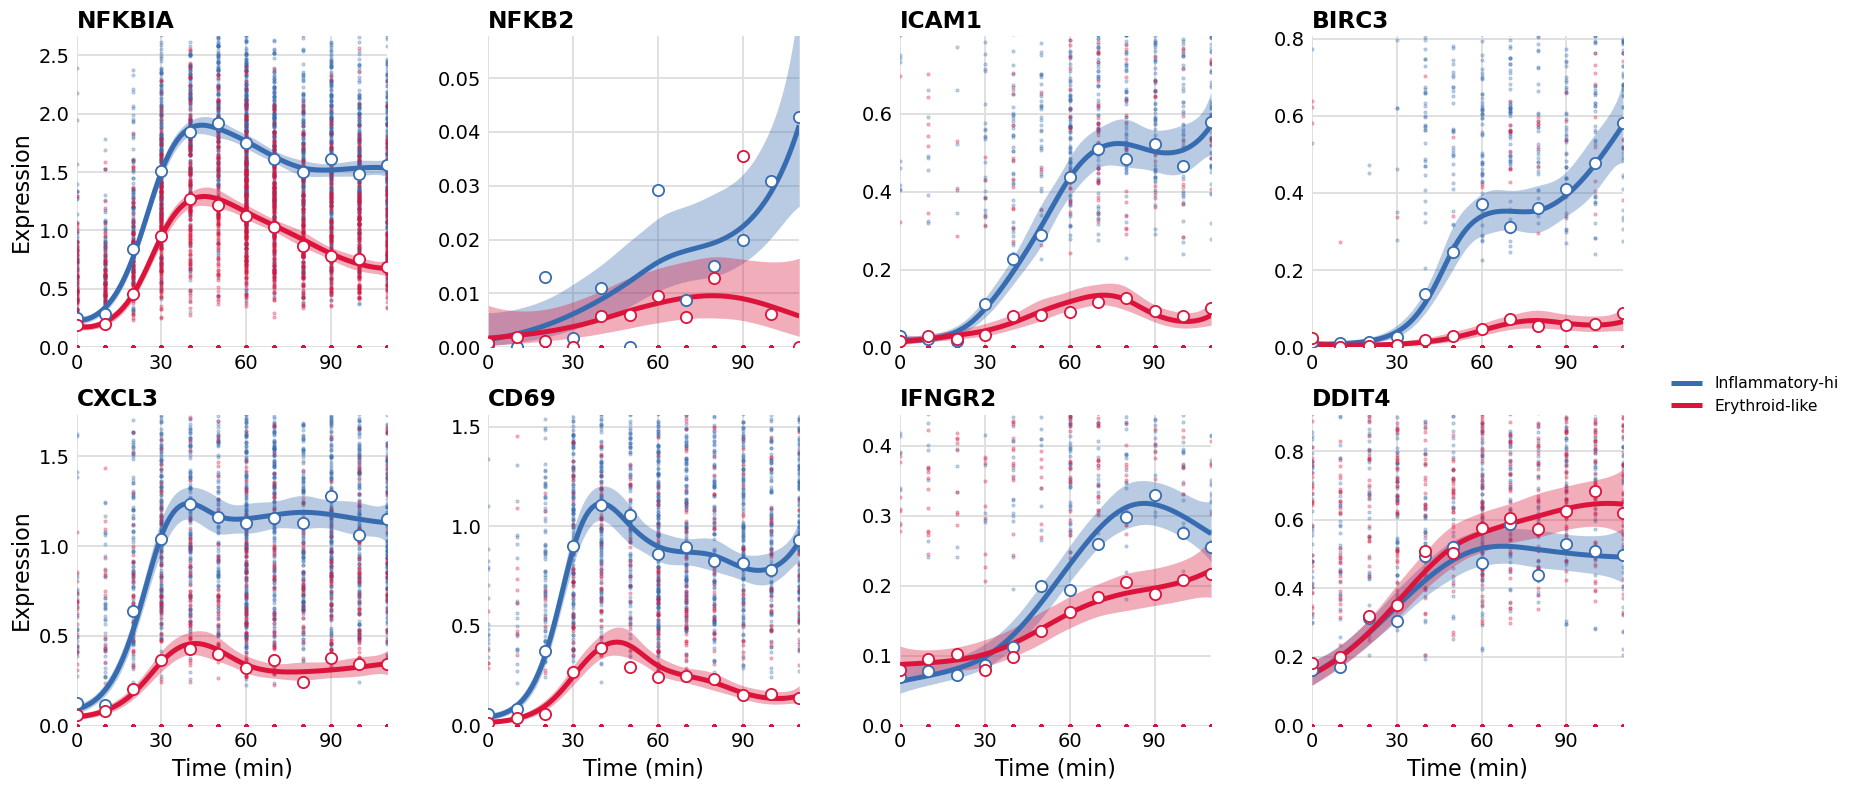

In [22]:
curves, observations = [], []
for lineage, cluster in [(1, "0"), (2, "1")]:
    name = FATE_NAMES[cluster]
    curves.append(cp.tl.predict_gene_dynamics(fit_fates, PANEL, lineage=lineage, time_max=TIME_MAX).assign(fate=name))
    observations.append(cp.tl.observed_gene_dynamics(fit_fates, PANEL, lineage=lineage, time_max=TIME_MAX).assign(fate=name))

fig = cp.pl.gene_dynamics_curves(
    pd.concat(curves),
    PANEL,
    observations=pd.concat(observations),
    group_col="fate",
    colors=FATE_COLORS,
    output=FIG_DIR / "fate_gene_curves.pdf",
)

## Where the results are

- `adata_hvg`: transition graph (`obsp["ot_graph"]`), OT-UMAP (`obsm["ot_umap"]`, `obsm["ot_umap_rot"]`), trajectory clusters, fate probabilities and soft memberships (`obs`).
- `adata_fit.var`: association tests of both fits (`gene_dynamics_*`, `gene_dynamics_fates_*`).
- `adata_*.uns["chronopack"]`: the parameters of every ChronoPack step that modified the object.
- `work/`: transport maps, tradeSeq inputs and fitted models, and the figures (PDF).

In [23]:
{name: entry["analysis"] for name, entry in adata_fit.uns["chronopack"].items()}

{'filter_technical_genes': 'preprocessing.filter_technical_genes', 'filter_low_count_genes': 'preprocessing.filter_low_count_genes', 'gene_dynamics': 'gene_dynamics', 'gene_dynamics_fates': 'gene_dynamics'}

**Next steps.** The full analyses in `analyses/` build on these outputs: clustering genes by the shape of their dynamics across experiments (`gene_clustering/`), cell-cell communication (`c2c/`) and gene-regulatory network inference (`grn/`).